# Financial Analysis — ABC Manufacturing (Steel)
## FY2024 – FY2025 (Q1/2024 – Q4/2025), Quarterly
**Mục đích:** Tính toàn bộ bộ KPI tài chính chuẩn (P&L, Margin, Profitability, Liquidity, Leverage, Cash Flow, Working Capital, Planning) từ 8 bảng dữ liệu nguồn, làm nền cho báo cáo Word gửi CFO.

**Nguồn dữ liệu:** dim_account.csv, dim_company.csv, dim_date.csv, dim_department.csv, fact_balance_sheet.csv, fact_budget.csv, fact_cashflow.csv, fact_income_statement.csv

### Setup & Load dữ liệu

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 10

dim_account       = pd.read_csv("dim_account.csv")
dim_company       = pd.read_csv("dim_company.csv")
dim_date          = pd.read_csv("dim_date.csv")
dim_department    = pd.read_csv("dim_department.csv")
balance_sheet     = pd.read_csv("fact_balance_sheet.csv")
budget            = pd.read_csv("fact_budget.csv")
cash_flow         = pd.read_csv("fact_cashflow.csv")
income_statement  = pd.read_csv("fact_income_statement.csv")

print("Company:", dim_company.loc[0, "Company"], "|", dim_company.loc[0, "Industry"],
      "|", dim_company.loc[0, "Currency"])
print("Periods:", ", ".join(dim_date.date_id.tolist()))
dim_date

Company: ABC Manufacturing | Steel Manufacturing | USD
Periods: 2024Q1, 2024Q2, 2024Q3, 2024Q4, 2025Q1, 2025Q2, 2025Q3, 2025Q4


,date_id,Year,Quarter,Start_Date,End_Date
0,2024Q1,2024,Q1,2024-01-01,2024-03-31
1,2024Q2,2024,Q2,2024-04-01,2024-06-30
2,2024Q3,2024,Q3,2024-07-01,2024-09-30
3,2024Q4,2024,Q4,2024-10-01,2024-12-31
4,2025Q1,2025,Q1,2025-01-01,2025-03-31
5,2025Q2,2025,Q2,2025-04-01,2025-06-30
6,2025Q3,2025,Q3,2025-07-01,2025-09-30
7,2025Q4,2025,Q4,2025-10-01,2025-12-31


In [25]:
# Department dimension
dim_department.head()

,department_id,Department
0,1,Sales
1,2,Marketing
2,3,Operations
3,4,Finance
4,5,HR


In [26]:
# Account
dim_account.head()

,account_id,Account,Statement
0,1001,Revenue,Income Statement
1,1002,COGS,Income Statement
2,1003,Selling Expense,Income Statement
3,1004,Marketing Expense,Income Statement
4,1005,G&A Expense,Income Statement


In [27]:
# Balance sheet
balance_sheet.head()

,date_id,Cash,AR,Inventory,Fixed_Assets,Other_Assets_Unreconciled,Total_Assets,AP,ST_Debt,LT_Debt,Equity,Total_Liab_Equity,Balance_Check,Data_Quality_Flag
0,2024Q1,220000,180000,260000,920000,0,1580000,140000,160000,420000,860000,1580000,0,OK
1,2024Q2,235000,185000,255000,930000,20000,1625000,145000,155000,415000,910000,1625000,0,PLUG - PENDING SOURCE VERIFICATION
2,2024Q3,250000,190000,245000,940000,45000,1670000,150000,150000,410000,960000,1670000,0,PLUG - PENDING SOURCE VERIFICATION
3,2024Q4,270000,200000,240000,950000,70000,1730000,155000,145000,400000,1030000,1730000,0,PLUG - PENDING SOURCE VERIFICATION
4,2025Q1,285000,205000,235000,970000,85000,1780000,160000,140000,390000,1090000,1780000,0,PLUG - PENDING SOURCE VERIFICATION


In [28]:
# Budget
budget.head()

,date_id,Budget_Revenue,Budget_COGS,Budget_NetProfit
0,2024Q1,1180000,710000,235000
1,2024Q2,1260000,750000,250000
2,2024Q3,1330000,785000,270000
3,2024Q4,1430000,835000,300000
4,2025Q1,1500000,865000,325000


In [29]:
# Cash flow
cash_flow.head()

,date_id,Operating_CF,Investing_CF,Financing_CF,CapEx
0,2024Q1,240000,-80000,-40000,80000
1,2024Q2,260000,-85000,-35000,85000
2,2024Q3,285000,-90000,-30000,90000
3,2024Q4,320000,-95000,-30000,95000
4,2025Q1,340000,-95000,-25000,95000


In [30]:
# Income statement
income_statement.head()

,date_id,Revenue,COGS,Selling,Marketing,G&A,Depreciation,Interest,Tax
0,2024Q1,1200000,720000,70000,45000,65000,25000,12000,42000
1,2024Q2,1280000,760000,73000,47000,67000,25000,12000,47000
2,2024Q3,1350000,790000,76000,50000,70000,26000,11500,52000
3,2024Q4,1450000,840000,80000,52000,72000,27000,11000,59000
4,2025Q1,1520000,870000,82000,54000,73000,27000,10500,64000


### Chuẩn bị dữ liệu (Data Preparation)

In [31]:
dim_date['Start_Date'] = pd.to_datetime(dim_date['Start_Date'])
dim_date['End_Date'] = pd.to_datetime(dim_date['End_Date'])
dim_date['days_in_period'] = (dim_date['End_Date'] - dim_date['Start_Date']).dt.days + 1

master = (income_statement.merge(balance_sheet, on='date_id')
             .merge(cash_flow, on='date_id')
             .merge(budget, on='date_id')
             .merge(dim_date[['date_id','Year','Quarter','days_in_period']], on='date_id'))
master['period_order'] = master['Year'].astype(str) + master['Quarter']
master = master.sort_values(['Year','Quarter']).reset_index(drop=True)

master

,date_id,Revenue,COGS,Selling,Marketing,G&A,Depreciation,Interest,Tax,Cash,...,Investing_CF,Financing_CF,CapEx,Budget_Revenue,Budget_COGS,Budget_NetProfit,Year,Quarter,days_in_period,period_order
0,2024Q1,1200000,720000,70000,45000,65000,25000,12000,42000,220000,...,-80000,-40000,80000,1180000,710000,235000,2024,Q1,91,2024Q1
1,2024Q2,1280000,760000,73000,47000,67000,25000,12000,47000,235000,...,-85000,-35000,85000,1260000,750000,250000,2024,Q2,91,2024Q2
2,2024Q3,1350000,790000,76000,50000,70000,26000,11500,52000,250000,...,-90000,-30000,90000,1330000,785000,270000,2024,Q3,92,2024Q3
3,2024Q4,1450000,840000,80000,52000,72000,27000,11000,59000,270000,...,-95000,-30000,95000,1430000,835000,300000,2024,Q4,92,2024Q4
4,2025Q1,1520000,870000,82000,54000,73000,27000,10500,64000,285000,...,-95000,-25000,95000,1500000,865000,325000,2025,Q1,90,2025Q1
5,2025Q2,1600000,900000,85000,56000,75000,28000,10000,70000,300000,...,-100000,-20000,100000,1580000,895000,345000,2025,Q2,91,2025Q2
6,2025Q3,1700000,940000,88000,58000,76000,29000,9500,76000,320000,...,-105000,-20000,105000,1680000,935000,370000,2025,Q3,92,2025Q3
7,2025Q4,1820000,990000,92000,60000,78000,30000,9000,84000,345000,...,-110000,-15000,110000,1800000,985000,405000,2025,Q4,92,2025Q4


### Income Statement KPIs
P&L waterfall:

```
Revenue
 (-) COGS                          =  Gross Profit
 (-) Selling, Marketing, G&A       =  EBITDA
 (-) Depreciation                  =  EBIT  (= Operating Profit)
 (-) Interest                      =  EBT (Pre-tax Profit)
 (-) Tax                           =  Net Profit (EAT)
```

In [32]:
waterfall = master[['date_id']].copy()
waterfall['Revenue']          = master['Revenue']
waterfall['Cost (COGS)']      = master['COGS']
waterfall['Gross Profit']     = master['Revenue'] - master['COGS']
waterfall['EBITDA']           = waterfall['Gross Profit'] - master['Selling'] - master['Marketing'] - master['G&A']
waterfall['Operating Profit (EBIT)']             = waterfall['EBITDA'] - master['Depreciation']
waterfall['EBT (Pre-tax)']    = waterfall['Operating Profit (EBIT)'] - master['Interest']
waterfall['Net Profit (EAT)'] = waterfall['EBT (Pre-tax)'] - master['Tax']

waterfall_display = waterfall.set_index('date_id')
waterfall_display

,Revenue,Cost (COGS),Gross Profit,EBITDA,Operating Profit (EBIT),EBT (Pre-tax),Net Profit (EAT)
date_id,,,,,,,
2024Q1,1200000,720000,480000,300000,275000,263000,221000
2024Q2,1280000,760000,520000,333000,308000,296000,249000
2024Q3,1350000,790000,560000,364000,338000,326500,274500
2024Q4,1450000,840000,610000,406000,379000,368000,309000
2025Q1,1520000,870000,650000,441000,414000,403500,339500
2025Q2,1600000,900000,700000,484000,456000,446000,376000
2025Q3,1700000,940000,760000,538000,509000,499500,423500
2025Q4,1820000,990000,830000,600000,570000,561000,477000


### Margin KPIs

In [33]:
margin = master[['date_id']].copy()
opex = master['Selling'] + master['Marketing'] + master['G&A'] + master['Depreciation']
sga  = master['Selling'] + master['G&A']   # SG&A = Selling + G&A

margin['Gross Margin %']     = waterfall['Gross Profit'] / waterfall['Revenue'] * 100
margin['Operating Margin %'] = waterfall['Operating Profit (EBIT)'] / waterfall['Revenue'] * 100
margin['Net Profit Margin %']= waterfall['Net Profit (EAT)'] / waterfall['Revenue'] * 100
margin['COGS Ratio %']       = master['COGS'] / waterfall['Revenue'] * 100
margin['OPEX Ratio %']       = opex / waterfall['Revenue'] * 100
margin['SG&A Ratio %']       = sga / waterfall['Revenue'] * 100

margin_display = margin.set_index('date_id')
margin_display.round(2)

,Gross Margin %,Operating Margin %,Net Profit Margin %,COGS Ratio %,OPEX Ratio %,SG&A Ratio %
date_id,,,,,,
2024Q1,40.00,22.92,18.42,60.00,17.08,11.25
2024Q2,40.62,24.06,19.45,59.38,16.56,10.94
2024Q3,41.48,25.04,20.33,58.52,16.44,10.81
2024Q4,42.07,26.14,21.31,57.93,15.93,10.48
2025Q1,42.76,27.24,22.34,57.24,15.53,10.20
2025Q2,43.75,28.50,23.50,56.25,15.25,10.00
2025Q3,44.71,29.94,24.91,55.29,14.76,9.65
2025Q4,45.60,31.32,26.21,54.40,14.29,9.34


### Profitability — ROA, ROE

In [34]:
profitability = master[['date_id']].copy()

avg_assets = (balance_sheet['Total_Assets'] + balance_sheet['Total_Assets'].shift(1)) / 2
avg_assets.iloc[0] = balance_sheet['Total_Assets'].iloc[0]
avg_equity = (balance_sheet['Equity'] + balance_sheet['Equity'].shift(1)) / 2
avg_equity.iloc[0] = balance_sheet['Equity'].iloc[0]

profitability['Avg Total Assets'] = avg_assets.values
profitability['Avg Equity']       = avg_equity.values
profitability['ROA % (quarterly)']  = waterfall['Net Profit (EAT)'] / profitability['Avg Total Assets'] * 100
profitability['ROE % (quarterly)']  = waterfall['Net Profit (EAT)'] / profitability['Avg Equity'] * 100
profitability['ROA % (annualized)'] = profitability['ROA % (quarterly)'] * 4
profitability['ROE % (annualized)'] = profitability['ROE % (quarterly)'] * 4

prof_display = profitability.set_index('date_id')
prof_display.round(2)

,Avg Total Assets,Avg Equity,ROA % (quarterly),ROE % (quarterly),ROA % (annualized),ROE % (annualized)
date_id,,,,,,
2024Q1,"1,580,000.00","860,000.00",13.99,25.70,55.95,102.79
2024Q2,"1,602,500.00","885,000.00",15.54,28.14,62.15,112.54
2024Q3,"1,647,500.00","935,000.00",16.66,29.36,66.65,117.43
2024Q4,"1,700,000.00","995,000.00",18.18,31.06,72.71,124.22
2025Q1,"1,755,000.00","1,060,000.00",19.34,32.03,77.38,128.11
2025Q2,"1,810,000.00","1,125,000.00",20.77,33.42,83.09,133.69
2025Q3,"1,875,000.00","1,200,000.00",22.59,35.29,90.35,141.17
2025Q4,"1,950,000.00","1,285,000.00",24.46,37.12,97.85,148.48


### Liquidity — Current Ratio, Quick Ratio

In [35]:
liquidity = master[['date_id']].copy()
current_liability = balance_sheet['AP'] + balance_sheet['ST_Debt']

liquidity['Current Assets']  = balance_sheet['Cash'] + balance_sheet['AR'] + balance_sheet['Inventory']
liquidity['Current Liabilities'] = current_liability
liquidity['Current Ratio (x)'] = liquidity['Current Assets'] / current_liability
liquidity['Quick Ratio (x)']   = (balance_sheet['Cash'] + balance_sheet['AR']) / current_liability

liq_display = liquidity.set_index('date_id')
liq_display.round(2)

,Current Assets,Current Liabilities,Current Ratio (x),Quick Ratio (x)
date_id,,,,
2024Q1,660000,300000,2.20,1.33
2024Q2,675000,300000,2.25,1.40
2024Q3,685000,300000,2.28,1.47
2024Q4,710000,300000,2.37,1.57
2025Q1,725000,300000,2.42,1.63
2025Q2,740000,300000,2.47,1.70
2025Q3,760000,300000,2.53,1.78
2025Q4,785000,300000,2.62,1.88


### Leverage — Debt-to-Equity, Interest Coverage

In [36]:
leverage = master[['date_id']].copy()
total_debt = balance_sheet['ST_Debt'] + balance_sheet['LT_Debt']

leverage['Total Debt'] = total_debt
leverage['Debt-to-Equity (x)']   = total_debt / balance_sheet['Equity']
leverage['Interest Coverage (x)'] = waterfall['Operating Profit (EBIT)'] / master['Interest']

lev_display = leverage.set_index('date_id')
lev_display.round(2)

,Total Debt,Debt-to-Equity (x),Interest Coverage (x)
date_id,,,
2024Q1,580000,0.67,22.92
2024Q2,570000,0.63,25.67
2024Q3,560000,0.58,29.39
2024Q4,545000,0.53,34.45
2025Q1,530000,0.49,39.43
2025Q2,515000,0.44,45.60
2025Q3,500000,0.40,53.58
2025Q4,485000,0.36,63.33


### Cash Flow KPIs
`Cash Conversion Ratio = OCF / Net Profit` (đo mức độ lợi nhuận sổ sách được chuyển hóa thành tiền mặt thực thu). 

`CapEx Ratio = CapEx / Revenue` (mức độ đầu tư tài sản cố định so với doanh thu).

In [37]:
cash_flow_kpis = master[['date_id']].copy()

cash_flow_kpis['OCF']  = master['Operating_CF']
cash_flow_kpis['FCF']  = master['Operating_CF'] - master['CapEx']
cash_flow_kpis['Operating Cash Flow Margin (%)'] = cash_flow_kpis['OCF'] / waterfall['Revenue'] * 100
cash_flow_kpis['FCF Conversion Ratio (x)'] = cash_flow_kpis['FCF'] / cash_flow_kpis['OCF']
cash_flow_kpis['FCF-to-OCF (%)'] = (cash_flow_kpis['FCF'] / cash_flow_kpis['OCF']) * 100
cash_flow_kpis['Free Cash Flow Margin (%)']      = cash_flow_kpis['FCF'] / waterfall['Revenue'] * 100
cash_flow_kpis['Cash Conversion Ratio (x)']    = cash_flow_kpis['OCF'] / waterfall['Net Profit (EAT)']
cash_flow_kpis['CapEx Ratio %'] = master['CapEx'] / waterfall['Revenue'] * 100
cash_flow_kpis['Operating Cash Flow Growth (%)']    = ((cash_flow_kpis['OCF'] - cash_flow_kpis['OCF'].shift(1)) 
                                                       / cash_flow_kpis['OCF'].shift(1) * 100)

cash_flow_kpis_display = cash_flow_kpis.set_index('date_id')
cash_flow_kpis_display.round(2)

,OCF,FCF,Operating Cash Flow Margin (%),FCF Conversion Ratio (x),FCF-to-OCF (%),Free Cash Flow Margin (%),Cash Conversion Ratio (x),CapEx Ratio %,Operating Cash Flow Growth (%)
date_id,,,,,,,,,
2024Q1,240000,160000,20.00,0.67,66.67,13.33,1.09,6.67,NaN
2024Q2,260000,175000,20.31,0.67,67.31,13.67,1.04,6.64,8.33
2024Q3,285000,195000,21.11,0.68,68.42,14.44,1.04,6.67,9.62
2024Q4,320000,225000,22.07,0.70,70.31,15.52,1.04,6.55,12.28
2025Q1,340000,245000,22.37,0.72,72.06,16.12,1.00,6.25,6.25
2025Q2,365000,265000,22.81,0.73,72.60,16.56,0.97,6.25,7.35
2025Q3,390000,285000,22.94,0.73,73.08,16.76,0.92,6.18,6.85
2025Q4,430000,320000,23.63,0.74,74.42,17.58,0.90,6.04,10.26


### Working Capital & Hiệu quả vận hành
`DIO/DSO/DPO` dùng số ngày thực tế của từng quý, và dùng Inventory/AR/AP bình quân đầu–cuối kỳ. Turnover được quy đổi theo năm (annualized) bằng công thức 365 / Days, đảm bảo nhất quán với DIO/DSO/DPO.

In [38]:
working_capital = master[['date_id']].copy()
days = master['days_in_period']

avg_inv = (balance_sheet['Inventory'] + balance_sheet['Inventory'].shift(1)) / 2
avg_inv.iloc[0] = balance_sheet['Inventory'].iloc[0]
avg_ar  = (balance_sheet['AR'] + balance_sheet['AR'].shift(1)) / 2
avg_ar.iloc[0] = balance_sheet['AR'].iloc[0]
avg_ap  = (balance_sheet['AP'] + balance_sheet['AP'].shift(1)) / 2
avg_ap.iloc[0] = balance_sheet['AP'].iloc[0]

working_capital['DIO (days)'] = avg_inv.values / master['COGS'] * days
working_capital['DSO (days)'] = avg_ar.values / waterfall['Revenue'] * days
working_capital['DPO (days)'] = avg_ap.values / master['COGS'] * days
working_capital['CCC (days)'] = working_capital['DIO (days)'] + working_capital['DSO (days)'] - working_capital['DPO (days)']

working_capital['Inventory Turnover (x/năm)']  = 365 / working_capital['DIO (days)']
working_capital['Receivable Turnover (x/năm)'] = 365 / working_capital['DSO (days)']
working_capital['Payable Turnover (x/năm)']    = 365 / working_capital['DPO (days)']

working_capital_display = working_capital.set_index('date_id')
working_capital_display.round(1)

,DIO (days),DSO (days),DPO (days),CCC (days),Inventory Turnover (x/năm),Receivable Turnover (x/năm),Payable Turnover (x/năm)
date_id,,,,,,,
2024Q1,32.90,13.60,17.70,28.80,11.10,26.70,20.60
2024Q2,30.80,13.00,17.10,26.70,11.80,28.10,21.40
2024Q3,29.10,12.80,17.20,24.70,12.50,28.60,21.20
2024Q4,26.60,12.40,16.70,22.20,13.70,29.50,21.90
2025Q1,24.60,12.00,16.30,20.30,14.90,30.40,22.40
2025Q2,23.50,11.80,16.40,18.90,15.50,30.90,22.20
2025Q3,22.30,11.50,16.40,17.40,16.40,31.70,22.30
2025Q4,20.70,11.00,16.00,15.60,17.70,33.20,22.80


### Planning — Budget Variance

In [39]:
planning = master[['date_id']].copy()

planning['Revenue Actual'] = waterfall['Revenue']
planning['Revenue Budget'] = master['Budget_Revenue']
planning['Revenue Achievement (%)'] = planning['Revenue Actual'] / planning['Revenue Budget'] * 100
planning['Revenue Variance %'] = (planning['Revenue Actual'] - planning['Revenue Budget']) / planning['Revenue Budget'] * 100

planning['COGS Actual'] = master['COGS']
planning['COGS Budget'] = master['Budget_COGS']
planning['COGS Variance %'] = (planning['COGS Actual'] - planning['COGS Budget']) / planning['COGS Budget'] * 100

planning['Net Profit Actual'] = waterfall['Net Profit (EAT)']
planning['Net Profit Budget'] = master['Budget_NetProfit']
planning['Net Profit Variance %'] = (planning['Net Profit Actual'] 
                                     - planning['Net Profit Budget']) / planning['Net Profit Budget'] * 100

planning_display = planning.set_index('date_id')
planning_display.round(2)

,Revenue Actual,Revenue Budget,Revenue Achievement (%),Revenue Variance %,COGS Actual,COGS Budget,COGS Variance %,Net Profit Actual,Net Profit Budget,Net Profit Variance %
date_id,,,,,,,,,,
2024Q1,1200000,1180000,101.69,1.69,720000,710000,1.41,221000,235000,-5.96
2024Q2,1280000,1260000,101.59,1.59,760000,750000,1.33,249000,250000,-0.40
2024Q3,1350000,1330000,101.50,1.50,790000,785000,0.64,274500,270000,1.67
2024Q4,1450000,1430000,101.40,1.40,840000,835000,0.60,309000,300000,3.00
2025Q1,1520000,1500000,101.33,1.33,870000,865000,0.58,339500,325000,4.46
2025Q2,1600000,1580000,101.27,1.27,900000,895000,0.56,376000,345000,8.99
2025Q3,1700000,1680000,101.19,1.19,940000,935000,0.53,423500,370000,14.46
2025Q4,1820000,1800000,101.11,1.11,990000,985000,0.51,477000,405000,17.78


### Bảng tổng hợp toàn bộ KPI (Consolidated KPI Summary)

In [40]:
kpi_summary = waterfall.copy()
for df in [margin, profitability, liquidity, leverage, cash_flow_kpis, working_capital, planning]:
    kpi_summary = kpi_summary.merge(df, on='date_id')

kpi_summary.set_index('date_id').round(2)

,Revenue,Cost (COGS),Gross Profit,EBITDA,Operating Profit (EBIT),EBT (Pre-tax),Net Profit (EAT),Gross Margin %,Operating Margin %,Net Profit Margin %,...,Revenue Actual,Revenue Budget,Revenue Achievement (%),Revenue Variance %,COGS Actual,COGS Budget,COGS Variance %,Net Profit Actual,Net Profit Budget,Net Profit Variance %
date_id,,,,,,,,,,,,,,,,,,,,,
2024Q1,1200000,720000,480000,300000,275000,263000,221000,40.00,22.92,18.42,...,1200000,1180000,101.69,1.69,720000,710000,1.41,221000,235000,-5.96
2024Q2,1280000,760000,520000,333000,308000,296000,249000,40.62,24.06,19.45,...,1280000,1260000,101.59,1.59,760000,750000,1.33,249000,250000,-0.40
2024Q3,1350000,790000,560000,364000,338000,326500,274500,41.48,25.04,20.33,...,1350000,1330000,101.50,1.50,790000,785000,0.64,274500,270000,1.67
2024Q4,1450000,840000,610000,406000,379000,368000,309000,42.07,26.14,21.31,...,1450000,1430000,101.40,1.40,840000,835000,0.60,309000,300000,3.00
2025Q1,1520000,870000,650000,441000,414000,403500,339500,42.76,27.24,22.34,...,1520000,1500000,101.33,1.33,870000,865000,0.58,339500,325000,4.46
2025Q2,1600000,900000,700000,484000,456000,446000,376000,43.75,28.50,23.50,...,1600000,1580000,101.27,1.27,900000,895000,0.56,376000,345000,8.99
2025Q3,1700000,940000,760000,538000,509000,499500,423500,44.71,29.94,24.91,...,1700000,1680000,101.19,1.19,940000,935000,0.53,423500,370000,14.46
2025Q4,1820000,990000,830000,600000,570000,561000,477000,45.60,31.32,26.21,...,1820000,1800000,101.11,1.11,990000,985000,0.51,477000,405000,17.78


### Trực quan hóa

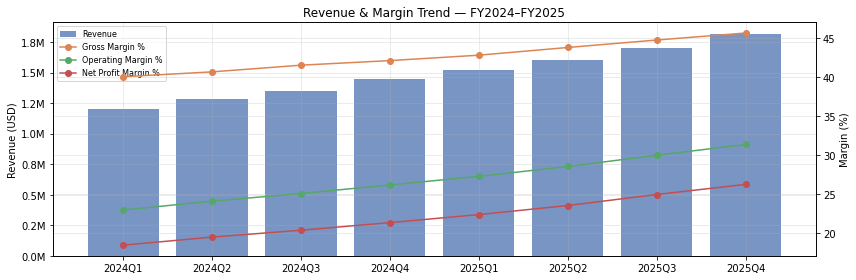

In [41]:
fig, ax1 = plt.subplots()
x = kpi_summary['date_id']
ax1.bar(x, kpi_summary['Revenue'], color='#4C72B0', alpha=0.75, label='Revenue')
ax1.set_ylabel('Revenue (USD)')
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f'{v/1e6:.1f}M'))

ax2 = ax1.twinx()
ax2.plot(x, margin['Gross Margin %'], marker='o', color='#DD8452', label='Gross Margin %')
ax2.plot(x, margin['Operating Margin %'], marker='o', color='#55A868', label='Operating Margin %')
ax2.plot(x, margin['Net Profit Margin %'], marker='o', color='#C44E52', label='Net Profit Margin %')
ax2.set_ylabel('Margin (%)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='upper left', fontsize=8)
plt.title('Revenue & Margin Trend — FY2024–FY2025')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Các phát hiện chính:**
- Doanh thu tăng đều trong cả tám quý, từ 1,20M lên 1,82M USD (+51,7% từ Q1/2024 đến Q4/2025), mỗi quý tăng 4,8–7,4% so với quý trước. Tính theo năm, FY2025 đạt 6,64M USD, cao hơn FY2024 (5,28M USD) khoảng 25,8%.
- Cả ba lớp biên lợi nhuận đều mở rộng liên tục: Gross Margin 40,0% → 45,6% (+5,6 điểm %), Operating Margin 22,9% → 31,3% (+8,4 điểm %), Net Profit Margin 18,4% → 26,2% (+7,8 điểm %).
- Khoảng 2/3 mức mở rộng Operating Margin đến từ giá vốn (COGS Ratio giảm từ 60,0% xuống 54,4%), khoảng 1/3 đến từ chi phí vận hành (OPEX Ratio giảm từ 17,1% xuống 14,3%). Giá vốn tăng 37,5% và chi phí vận hành tăng khoảng 27%, đều thấp hơn mức tăng doanh thu 51,7%, tạo hiệu ứng đòn bẩy hoạt động rõ rệt.
- Lợi nhuận ròng tăng khoảng 116%, gấp hơn hai lần tốc độ tăng doanh thu. Đà mở rộng biên chưa có dấu hiệu chững lại: Operating Margin vẫn tăng thêm 1,4 điểm % trong Q4/2025.
- Lưu ý: Net Profit Margin ~26% cao hơn nhiều so với mặt bằng thường thấy của ngành thép, cần đối chiếu nguồn dữ liệu và cách ghi nhận chi phí trước khi dùng làm mốc kế hoạch.

**Các khuyến nghị chiến lược**
1. Phân rã nguyên nhân giảm giá vốn (giá nguyên liệu đầu vào, hiệu suất sản xuất, giá bán và cơ cấu sản phẩm) để xác định đâu là cải thiện bền vững, đâu là yếu tố chu kỳ, vì COGS đóng góp phần lớn vào mức mở rộng biên.
2. Duy trì kỷ luật chi phí để chi phí vận hành tiếp tục tăng chậm hơn doanh thu, đồng thời không cắt giảm Selling và Marketing ở mức làm ảnh hưởng đà tăng trưởng.
3. Xây dựng kịch bản kiểm tra sức chịu đựng (stress test) cho biên lợi nhuận, ví dụ giá nguyên liệu tăng hoặc giá thép giảm, vì Gross Margin 45,6% đang ở mức cao nhất trong giai đoạn.
4. Thiết lập ngưỡng cảnh báo sớm cho COGS Ratio và OPEX Ratio trong báo cáo định kỳ để lãnh đạo kịp phản ứng khi biên đảo chiều.

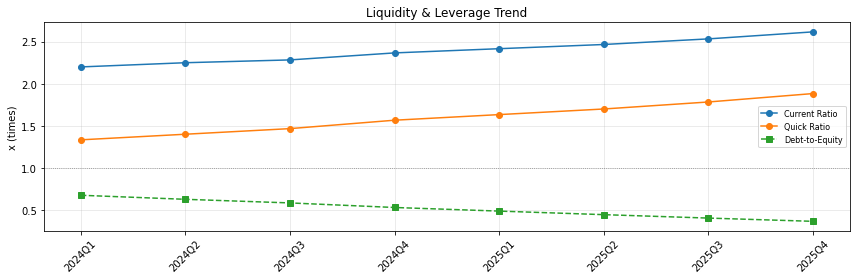

In [42]:
fig, ax = plt.subplots()
ax.plot(x, liquidity['Current Ratio (x)'], marker='o', label='Current Ratio')
ax.plot(x, liquidity['Quick Ratio (x)'], marker='o', label='Quick Ratio')
ax.plot(x, leverage['Debt-to-Equity (x)'], marker='s', linestyle='--', label='Debt-to-Equity')
ax.axhline(1, color='grey', linewidth=0.8, linestyle=':')
ax.set_title('Liquidity & Leverage Trend')
ax.set_ylabel('x (times)')
ax.legend(fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Các phát hiện chính:**
- Thanh khoản cải thiện đều: Current Ratio tăng từ 2,20x lên 2,62x, Quick Ratio từ 1,33x lên 1,88x. Nợ ngắn hạn giữ phẳng ở mức 300K USD suốt tám quý, trong khi tài sản ngắn hạn tăng từ 660K lên 785K USD (+19%), chủ yếu nhờ tiền mặt tăng từ 220K lên 345K USD (+57%).
- Đòn bẩy tài chính giảm mạnh: Debt-to-Equity giảm từ 0,67x xuống 0,36x, do tổng nợ vay giảm từ 580K xuống 485K USD (−16%) trong khi vốn chủ sở hữu tăng khoảng 55%. Nợ ròng (nợ vay trừ tiền mặt) giảm từ 360K xuống 140K USD, tương đương khoảng 0,07x EBITDA 12 tháng gần nhất.
- Khả năng trả lãi rất an toàn: Interest Coverage tăng từ 22,9x lên 63,3x nhờ EBIT tăng gấp đôi và chi phí lãi vay giảm từ 12,0K xuống 9,0K USD mỗi quý.
- Cả hai chỉ số thanh khoản đều cao hơn nhiều so với ngưỡng 1x và D/E thấp hơn nhiều so với 1x, cho thấy không có áp lực thanh khoản hay nợ vay. Ngược lại, tiền mặt và dư địa vay đang tích lũy nhưng chưa thấy được sử dụng, có thể là nguồn lực nhàn rỗi.
- Lưu ý: Current Liabilities hiện chỉ gồm AP và nợ ngắn hạn (chưa có thuế phải nộp, chi phí phải trả), và tiền mặt trên bảng cân đối chưa khớp với báo cáo lưu chuyển tiền tệ (xem mục kiểm tra dữ liệu), nên các tỷ số này có thể đang phản ánh tốt hơn thực tế.

**Các khuyến nghị chiến lược**
1. Xây dựng chính sách sử dụng nguồn tiền dư: xác định mức thanh khoản mục tiêu hợp lý, phần vượt mức ưu tiên cho đầu tư mở rộng có hiệu quả, chi trả cổ tức hoặc tất toán các khoản vay có chi phí cao.
2. Tận dụng dư địa đòn bẩy (D/E 0,36x, Interest Coverage 63x) để tài trợ cho kế hoạch tăng trưởng bằng nợ chi phí thấp, kết hợp xem xét tái cơ cấu kỳ hạn và lãi suất, nhưng giữ biên an toàn vì ngành thép mang tính chu kỳ.
3. Bổ sung vào bộ KPI các chỉ tiêu Net Debt/EBITDA, mức đệm so với covenant vay và đầy đủ các khoản nợ ngắn hạn, để đánh giá thanh khoản sát thực tế hơn.
4. Đối soát số dư tiền mặt và khoản tài sản chưa đối chiếu được (Other_Assets_Unreconciled) trước khi dùng kết luận thanh khoản làm cơ sở quyết định phân bổ vốn.

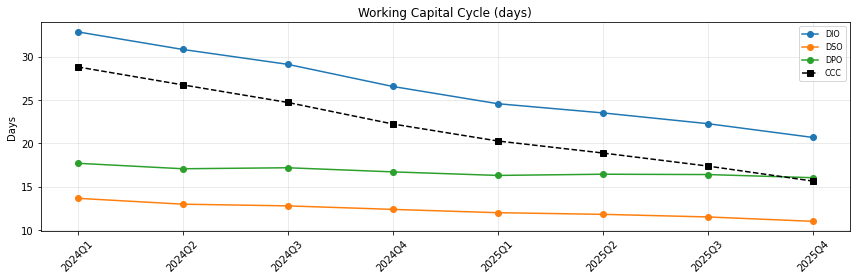

In [43]:
fig, ax = plt.subplots()
ax.plot(x, working_capital['DIO (days)'], marker='o', label='DIO')
ax.plot(x, working_capital['DSO (days)'], marker='o', label='DSO')
ax.plot(x, working_capital['DPO (days)'], marker='o', label='DPO')
ax.plot(x, working_capital['CCC (days)'], marker='s', linestyle='--', color='black', label='CCC')
ax.set_title('Working Capital Cycle (days)')
ax.set_ylabel('Days')
ax.legend(fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Các phát hiện chính:**
- Chu kỳ chuyển đổi tiền mặt (CCC) rút ngắn gần một nửa, từ 28,8 xuống 15,6 ngày (−13,2 ngày, −46%).
- Mức cải thiện đến chủ yếu từ tồn kho: DIO giảm từ 32,9 xuống 20,7 ngày (−12,2 ngày), tương ứng vòng quay tồn kho tăng từ 11,1x lên 17,7x. Tồn kho bình quân giảm trong khi giá vốn tăng 37,5%. DSO giảm từ 13,6 xuống 11,0 ngày (−2,6 ngày), đóng góp thêm một phần nhỏ.
- DPO giảm nhẹ từ 17,7 xuống 16,0 ngày, tức doanh nghiệp đang trả nhà cung cấp nhanh hơn một chút và làm mất khoảng 1,7 ngày của mức cải thiện CCC. Đường CCC đang tiến sát đường DPO và DSO, cho thấy dư địa cải thiện tiếp từ DIO và DSO không còn nhiều.
- Cảnh báo chéo: CCC cải thiện nhưng Cash Conversion Ratio (OCF/Lợi nhuận ròng) lại giảm từ 1,09x xuống 0,90x và dưới 1,0x từ Q2/2025. Vốn lưu động tối ưu hơn lẽ ra phải hỗ trợ dòng tiền, vì vậy cần kiểm tra thêm các khoản chi tiền khác (thuế, lãi, khoản phải trả khác) hoặc chất lượng dữ liệu.

**Các khuyến nghị chiến lược**
1. Không tiếp tục siết tồn kho. Với ngành thép, tồn kho quá mỏng làm tăng rủi ro đứt gãy nguyên liệu và rủi ro biến động giá, nên cần đặt mức tồn kho an toàn tối thiểu và ngưỡng cảnh báo cho DIO.
2. Đàm phán lại điều khoản thanh toán với nhà cung cấp chính để đưa DPO về mức cũ hoặc cao hơn. Theo giá vốn Q4/2025, mỗi ngày DPO tăng thêm tương đương khoảng 10,8K USD tiền mặt.
3. Với DSO đã thấp, tập trung giữ chất lượng khoản phải thu (phân tích tuổi nợ, hạn mức tín dụng theo nhóm khách hàng) thay vì siết thêm thời hạn thu tiền.
4. Làm rõ vì sao CCC cải thiện nhưng Cash Conversion Ratio suy giảm, và đưa cả hai chỉ số vào cùng một bảng theo dõi hằng quý.

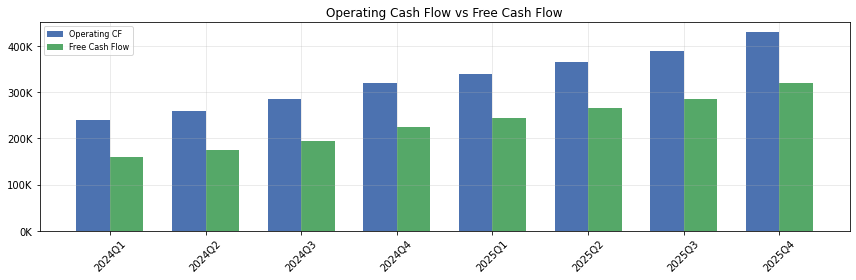

In [44]:
fig, ax = plt.subplots()
width = 0.35
idx = np.arange(len(x))
ax.bar(idx - width/2, cash_flow_kpis['OCF'], width, label='Operating CF', color='#4C72B0')
ax.bar(idx + width/2, cash_flow_kpis['FCF'], width, label='Free Cash Flow', color='#55A868')
ax.set_xticks(idx)
ax.set_xticklabels(x, rotation=45)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f'{v/1e3:.0f}K'))
ax.set_title('Operating Cash Flow vs Free Cash Flow')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Các phát hiện chính:**
- Dòng tiền từ hoạt động kinh doanh (OCF) tăng khoảng 79% (từ 240K lên 430K USD, Q1/2024 → Q4/2025). Tính theo năm, OCF FY2025 đạt 1,53M USD, cao hơn FY2024 khoảng 38%.
- Dòng tiền tự do (FCF) tăng gấp đôi (160K → 320K USD) và dương trong cả tám quý. FCF Margin tăng từ 13,3% lên 17,6%.
- Tỷ lệ FCF/OCF cải thiện từ 66,7% lên 74,4% do CapEx tăng chậm hơn OCF (+37,5% so với +79%); CapEx/Doanh thu giảm từ 6,7% xuống 6,0%.
- Tuy nhiên, OCF tăng chậm hơn lợi nhuận ròng (+79% so với +116%), khiến Cash Conversion Ratio giảm từ 1,09x xuống 0,90x và xuống dưới 1,0x từ Q2/2025. Lợi nhuận đang được chuyển hóa thành tiền kém hơn trước, dù dòng tiền tuyệt đối vẫn tăng mạnh.

**Các khuyến nghị chiến lược**
1. Điều tra nguyên nhân Cash Conversion Ratio giảm (thuế, lãi vay đã trả, biến động các khoản phải thu/phải trả, chi phí trả trước) và đặt mục tiêu đưa chỉ số này trở lại tối thiểu 1,0x.
2. Đánh giá hiệu quả của CapEx theo từng dự án (ROI, thời gian hoàn vốn) và ưu tiên các khoản đầu tư có lợi suất hấp dẫn, vì CapEx vẫn chiếm khoảng 6% doanh thu.
3. Xây dựng kế hoạch sử dụng FCF (đầu tư, giảm nợ, chi trả cổ tức) cụ thể, vì FCF tích lũy lớn nhưng số dư tiền mặt tăng chậm hơn nhiều (xem mục kiểm tra dữ liệu).
4. Theo dõi đồng thời OCF, FCF, Cash Conversion Ratio và thanh khoản trong báo cáo hằng quý để đảm bảo tăng trưởng lợi nhuận đi cùng dòng tiền thực thu.

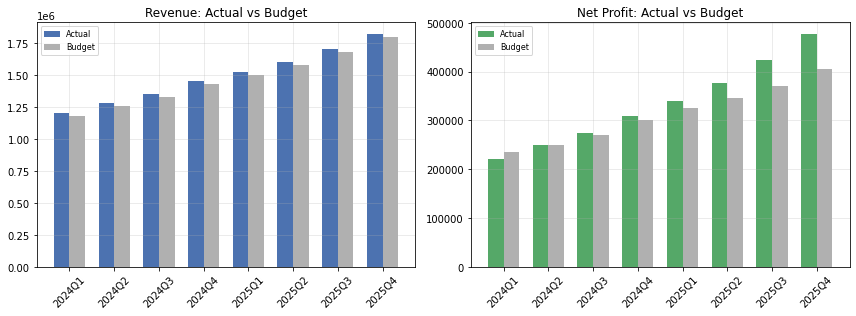

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(idx - width/2, planning['Revenue Actual'], width, label='Actual', color='#4C72B0')
axes[0].bar(idx + width/2, planning['Revenue Budget'], width, label='Budget', color='#B0B0B0')
axes[0].set_xticks(idx); axes[0].set_xticklabels(x, rotation=45)
axes[0].set_title('Revenue: Actual vs Budget')
axes[0].legend(fontsize=8)

axes[1].bar(idx - width/2, planning['Net Profit Actual'], width, label='Actual', color='#55A868')
axes[1].bar(idx + width/2, planning['Net Profit Budget'], width, label='Budget', color='#B0B0B0')
axes[1].set_xticks(idx); axes[1].set_xticklabels(x, rotation=45)
axes[1].set_title('Net Profit: Actual vs Budget')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Các phát hiện chính:**
- Doanh thu vượt kế hoạch trong cả tám quý, nhưng mức vượt nhỏ và thu hẹp dần, từ 101,7% xuống 101,1% (chênh lệch tuyệt đối gần như cố định ~20K USD mỗi quý). Chi phí giá vốn thực tế cũng cao hơn ngân sách ở cả tám quý (+0,5% đến +1,4%), nhưng thấp hơn mức vượt của doanh thu.
- Điểm đáng chú ý nhất là lợi nhuận ròng: từ thấp hơn kế hoạch ở Q1/2024 (−6,0%) và Q2/2024 (−0,4%), chuyển sang vượt kế hoạch ở sáu quý liên tiếp, với mức vượt tăng dần từ +1,7% lên +17,8% ở Q4/2025.
- Lợi nhuận ròng tăng khoảng 116%, vượt xa mức tăng doanh thu 52%, và Net Profit Margin cải thiện từ khoảng 18,4% lên 26,2%. Điều này cho thấy ngân sách lợi nhuận chưa phản ánh kịp mức mở rộng biên.

**Các khuyến nghị chiến lược**
1. Điều chỉnh phương pháp lập ngân sách lợi nhuận, dựa trên biên lợi nhuận thực tế gần nhất thay vì chỉ tăng theo doanh thu, để chênh lệch kế hoạch/thực tế phản ánh đúng hiệu quả điều hành.
2. Phân tích các yếu tố tạo nên mức vượt lợi nhuận (giá vốn, chi phí vận hành, cơ cấu sản phẩm) để quyết định phần nào có thể duy trì khi đặt mục tiêu năm tới.
3. Duy trì đà tăng trưởng doanh thu bằng cách tập trung vào các sản phẩm, nhóm khách hàng và kênh bán hàng hiệu quả cao, đồng thời kiểm soát giá vốn thực tế đang cao hơn ngân sách.
4. Theo dõi chênh lệch kế hoạch/thực tế theo quý cho doanh thu, COGS và lợi nhuận ròng; mức lệch lớn kéo dài nên kích hoạt rà soát lại ngân sách giữa kỳ.

In [46]:
kpi_summary.to_csv("kpi_summary.csv", index=False)